# Project 2

In [101]:
import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import numpy as np
import re
import matplotlib.patches as mpatches
import matplotlib.lines as mlines


## Data 1

**Data Source Information:**

* **Dataset:** asoiaf (A Song of Ice and Fire)
* **Author:** mathbeveridge
* **Source:** https://github.com/mathbeveridge/asoiaf
* **Modifications:** Merged multiple CSV files
* **License:** Data provided under the [CC BY-NC-SA 4.0](https://creativecommons.org/licenses/by-nc-sa/4.0/) license.

In [4]:
import pandas as pd

BASE = "https://raw.githubusercontent.com/mathbeveridge/asoiaf/master/data"

edges = pd.read_csv(f"{BASE}/asoiaf-all-edges.csv")
nodes = pd.read_csv(f"{BASE}/asoiaf-all-nodes.csv")

# print(edges.head())
# print(nodes.head())
print(f"Edges: {len(edges)}, Nodes: {len(nodes)}")

Edges: 2823, Nodes: 796


In [5]:
G = nx.from_pandas_edgelist(
    edges,
    source="Source",
    target="Target",
    edge_attr="weight",
)
print(G.number_of_nodes(), G.number_of_edges())

796 2823


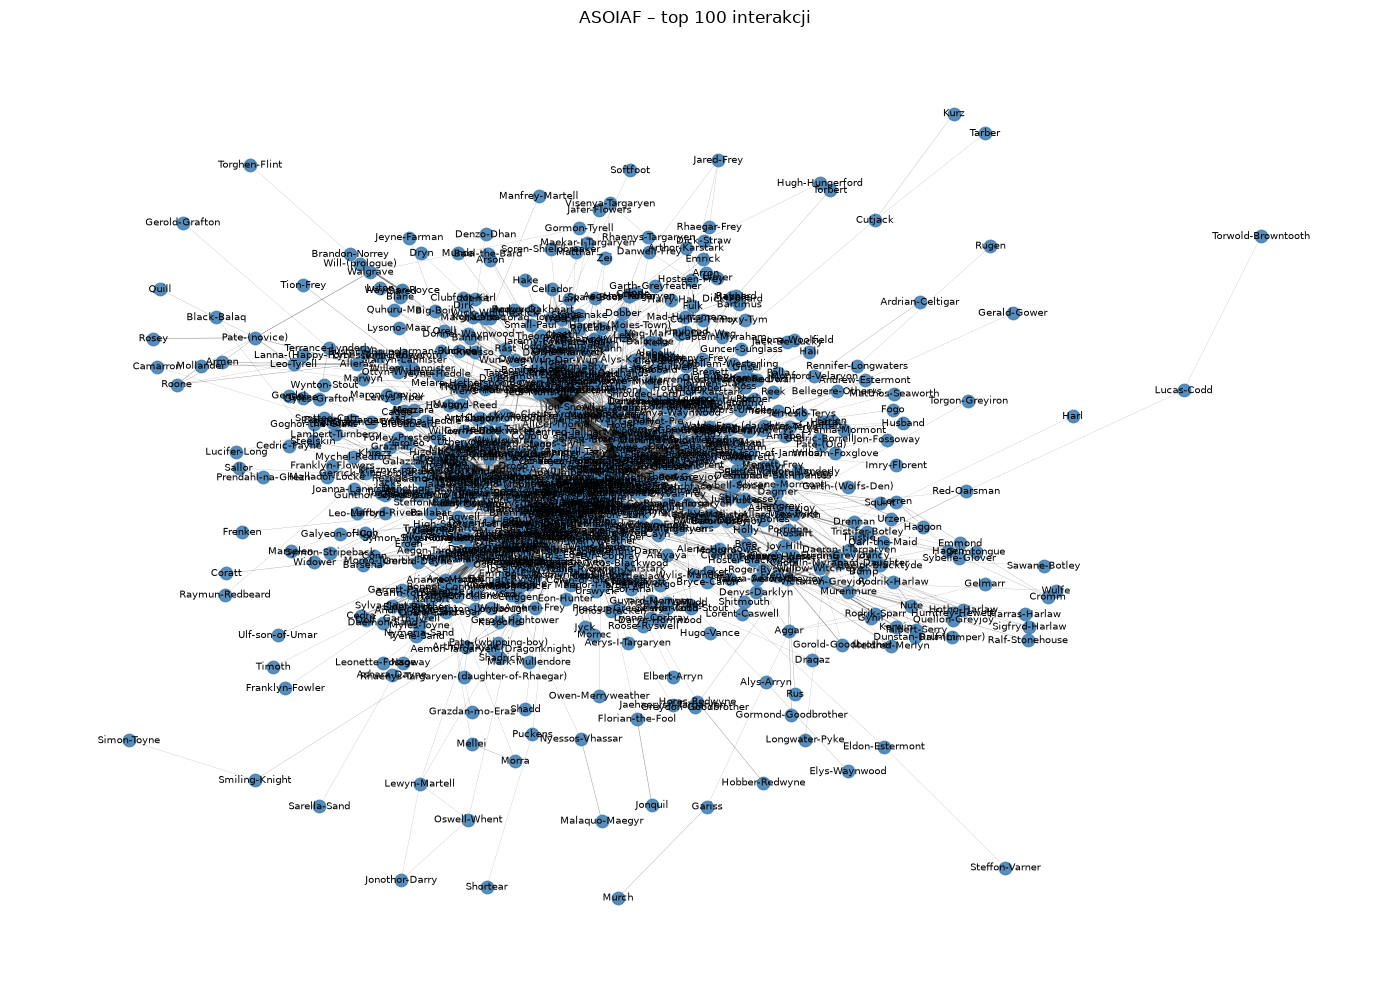

In [8]:
plt.figure(figsize=(14, 10))
pos = nx.spring_layout(G, k=0.5, seed=42)
weights = [G[u][v]["weight"] for u, v in G.edges()]
nx.draw_networkx_nodes(G, pos, node_size=80, node_color="steelblue", alpha=0.9)
nx.draw_networkx_edges(G, pos, width=[w / 20 for w in weights], alpha=0.4)
nx.draw_networkx_labels(G, pos, font_size=7)
plt.title("ASOIAF – top 100 interakcji")
plt.axis("off")
plt.tight_layout()
plt.show()

- The full graph of around 800 nodes is completely nonreadable. Typical and obvious for real-life networks.

Full: 796 nodes, 2823 edges
deg >= 20: 58 nodes, 484 edges


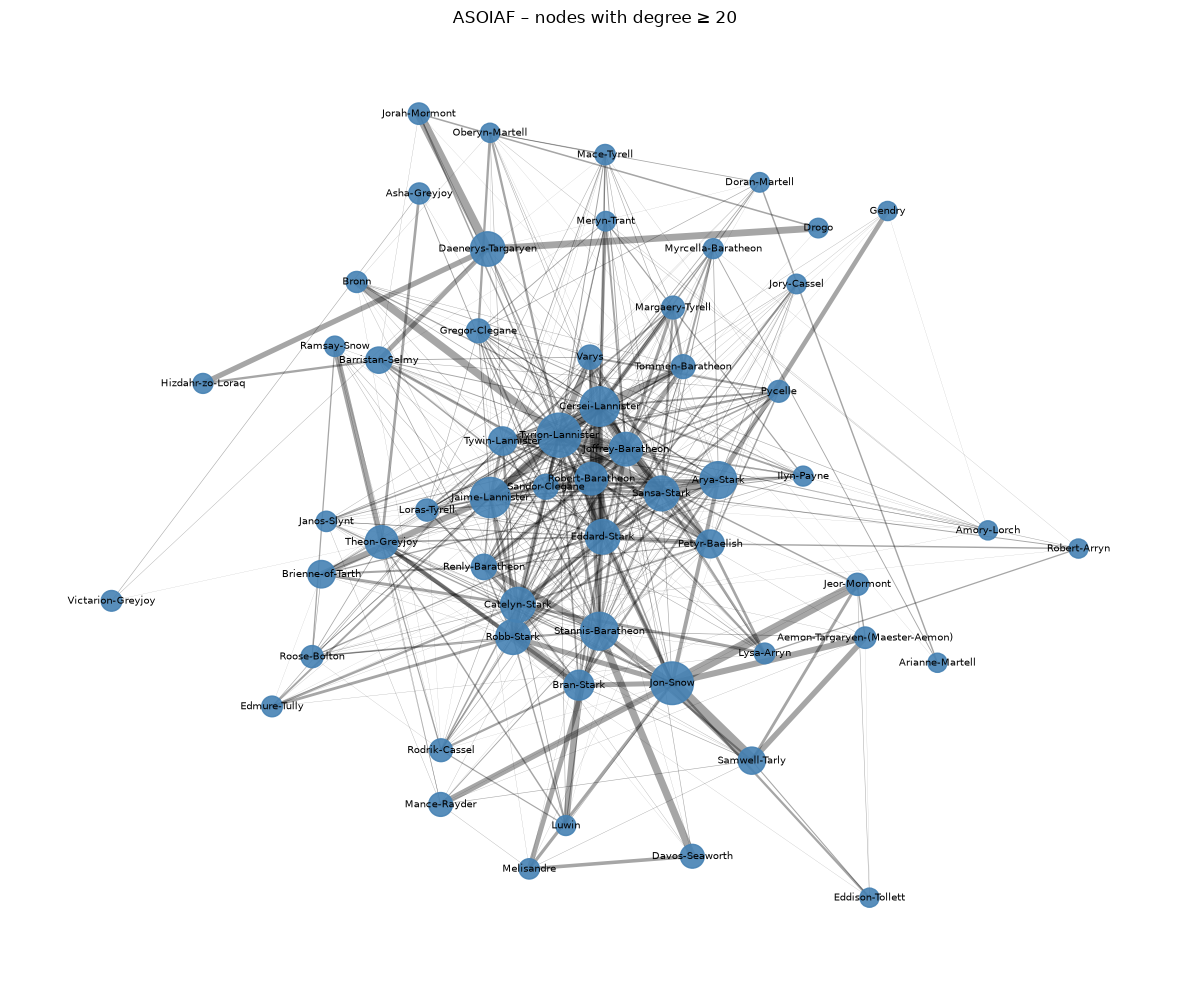

In [12]:
DEGREE_LIMIT = 20

deg = dict(G.degree())
keep = [n for n, d in deg.items() if d >= DEGREE_LIMIT]
H = G.subgraph(keep).copy()
H.remove_nodes_from(list(nx.isolates(H)))

print(f"Full: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")
print(f"deg >= {DEGREE_LIMIT}: {H.number_of_nodes()} nodes, {H.number_of_edges()} edges")

plt.figure(figsize=(12, 10))
pos = nx.spring_layout(H, k=3, seed=42, weight="weight")

sizes = [30 + deg[n] * 8 for n in H.nodes()]
weights = [H[u][v]["weight"] for u, v in H.edges()]

nx.draw_networkx_nodes(H, pos, node_size=sizes, node_color="steelblue", alpha=0.9)
nx.draw_networkx_edges(H, pos, width=[w / 25 for w in weights], alpha=0.35)
nx.draw_networkx_labels(H, pos, font_size=7)

plt.title(f"ASOIAF – nodes with degree ≥ {DEGREE_LIMIT}")
plt.axis("off")
plt.tight_layout()
plt.show()

Full: 796 nodes, 2823 edges
deg >= 30: 29 nodes, 234 edges


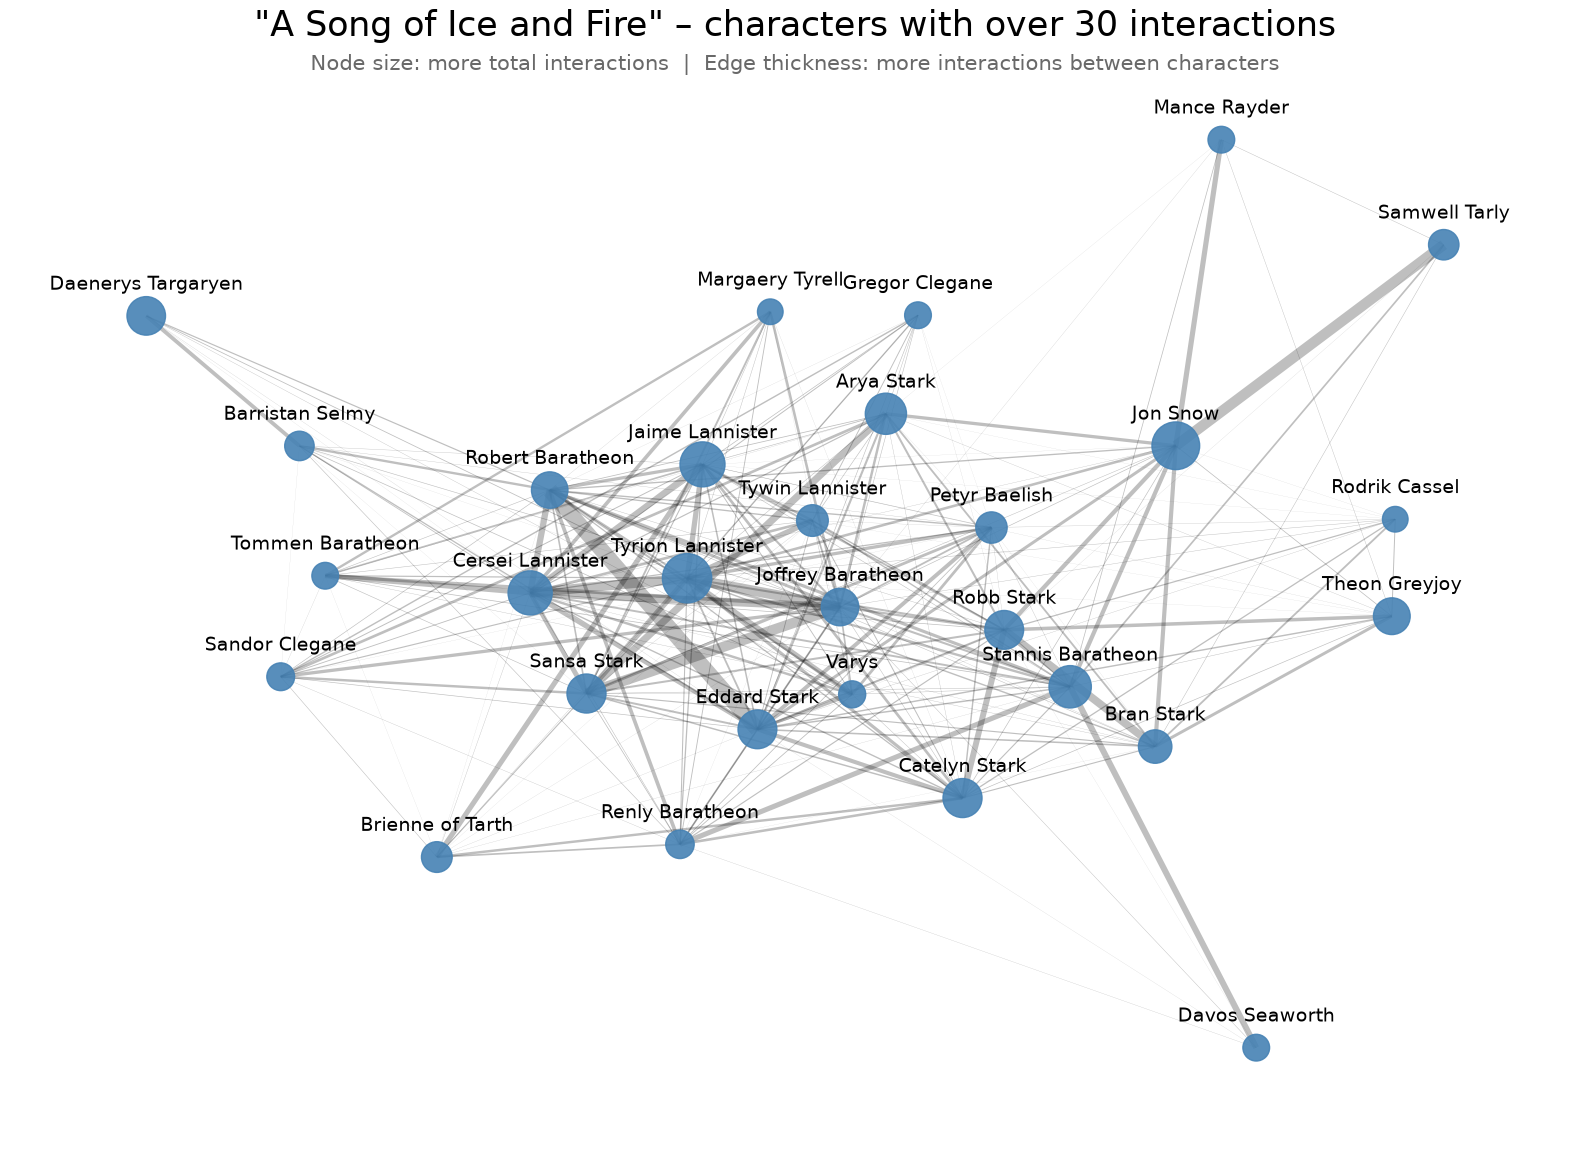

In [30]:
DEGREE_LIMIT = 30

deg = dict(G.degree())
keep = [n for n, d in deg.items() if d >= DEGREE_LIMIT]
H = G.subgraph(keep).copy()
H.remove_nodes_from(list(nx.isolates(H)))

print(f"Full: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")
print(f"deg >= {DEGREE_LIMIT}: {H.number_of_nodes()} nodes, {H.number_of_edges()} edges")

plt.figure(figsize=(16, 12))
pos = nx.spring_layout(H, k=2.5, seed=42, weight=None, iterations=100)

sizes = [40 + deg[n] * 10 for n in H.nodes()]
weights = [H[u][v]["weight"] for u, v in H.edges()]

labels = {n: n.replace("-", " ") for n in H.nodes()}

nx.draw_networkx_nodes(H, pos, node_size=sizes, node_color="steelblue", alpha=0.9)
nx.draw_networkx_edges(H, pos, width=[w / 30 for w in weights], alpha=0.25)

# Move node labels above each node
label_offset = 0.045  # fudge this value if overlap occurs
for n, (x, y) in pos.items():
    plt.text(
        x, 
        y + label_offset,  # above node, use y - label_offset for below
        labels[n],
        fontsize=14, 
        ha='center', 
        va='bottom',
    )

plt.title(f"\"A Song of Ice and Fire\" – characters with over {DEGREE_LIMIT} interactions", fontsize=25)
plt.suptitle(
    "Node size: more total interactions  |  Edge thickness: more interactions between characters",
    fontsize=15,
    y=0.92,
    color="dimgray"
)
plt.axis("off")
plt.tight_layout()
plt.show()

- Filtering to higher degree characters shows a heavy-tailed degree distribution. There are a few hubs (e.g. Jon), communities (around Tyrion) and a lot of low-degree characters.

## Multilayer network: layers = books, nodes = top-15 hubs, edges = inter-layer links between occurrences in top 15 hubs of the same character across books.

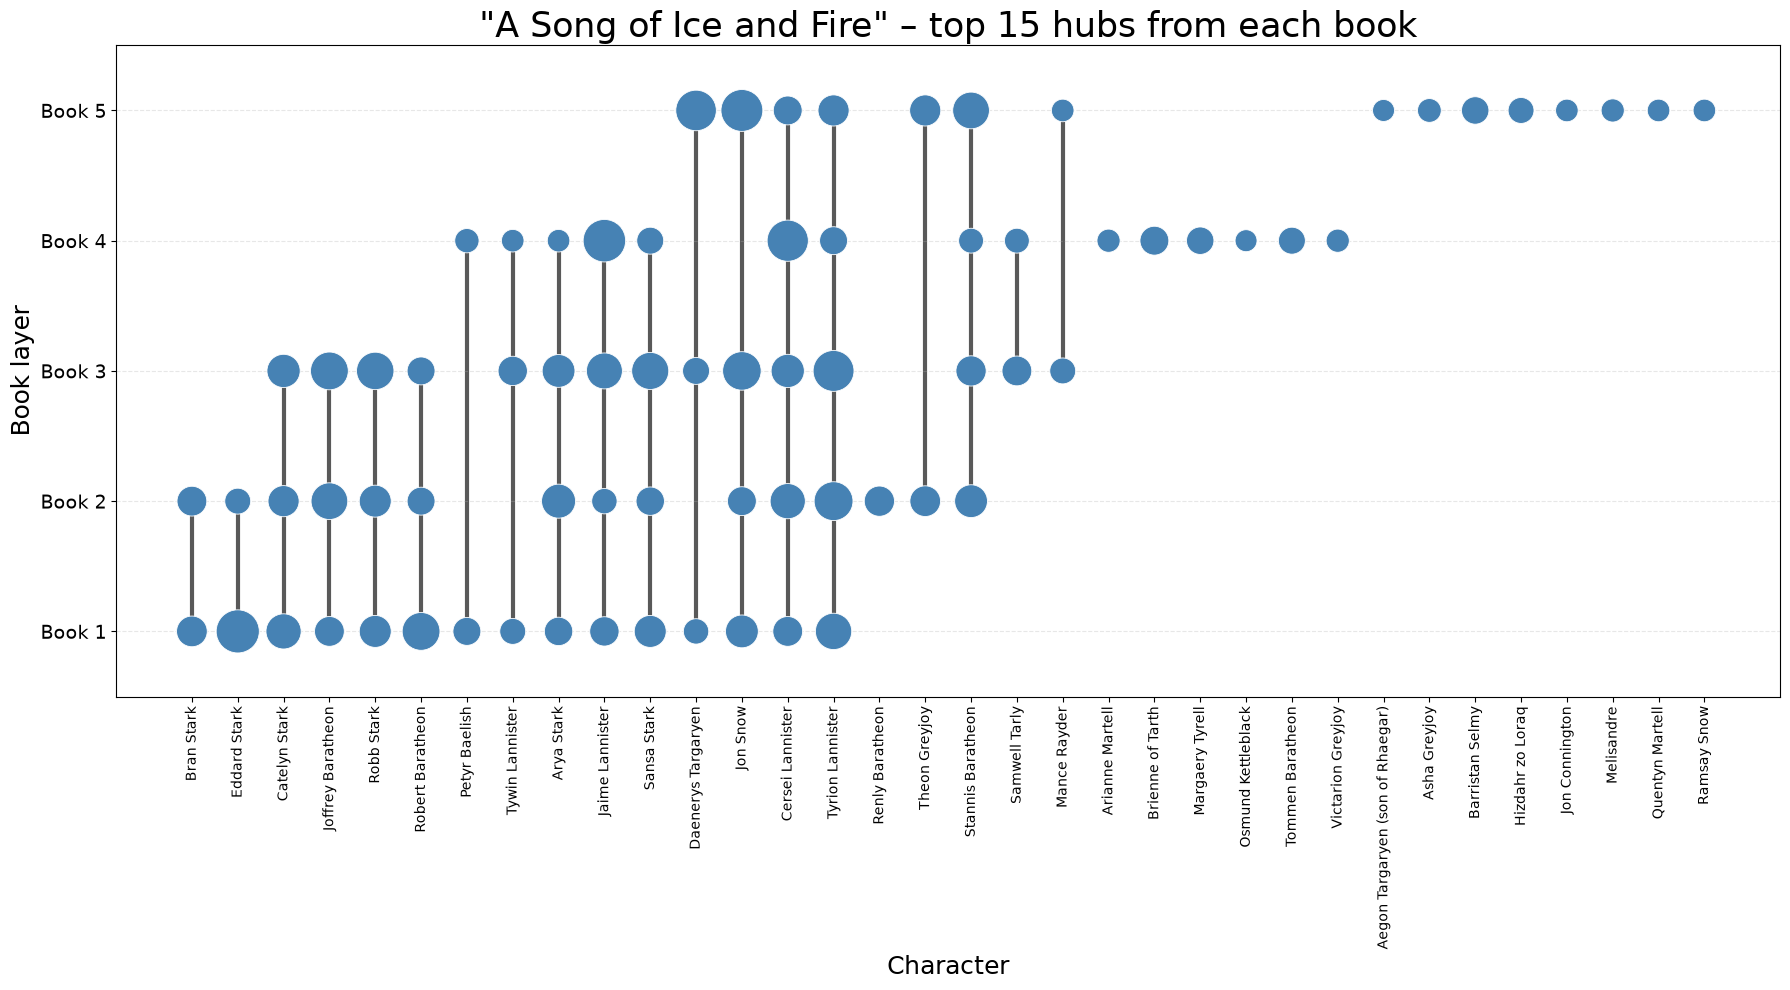

In [ ]:
TOP_N = 15

books = {b: pd.read_csv(f"{BASE}/asoiaf-book{b}-edges.csv") for b in range(1, 6)}

graphs = {}
hubs_per_book = {}
for b, edges in books.items():
    G = nx.from_pandas_edgelist(edges, "Source", "Target", edge_attr="weight")
    # degree in the full book network of all characters
    deg = dict(G.degree())
    hubs = sorted(deg, key=deg.get, reverse=True)[:TOP_N]
    H = G.subgraph(hubs).copy()
    graphs[b] = (H, deg)
    hubs_per_book[b] = set(H.nodes())

all_hubs = set().union(*hubs_per_book.values())

# used to sort hubs "chronologically"
def book_span(n):
    present = [b for b in range(1, 6) if n in hubs_per_book[b]]
    return min(present), max(present), len(present)

all_hubs = sorted(all_hubs, key=lambda n: (*book_span(n), n))
x_pos = {n: i for i, n in enumerate(all_hubs)}

fig, ax = plt.subplots(figsize=(18, 10))

# vertical lines
for n in all_hubs:
    ys = [b for b in range(1, 6) if n in hubs_per_book[b]]
    if len(ys) >= 2:
        ax.plot([x_pos[n]] * len(ys), ys, color="0.35", lw=3, zorder=0)

for b in range(1, 6):
    H, deg = graphs[b]
    y = b
    xs = [x_pos[n] for n in H.nodes()]
    sizes = [40 + deg[n] * 14 for n in H.nodes()]
    ax.scatter(
        xs, [y] * len(xs),
        s=sizes,
        c="steelblue",
        zorder=3,
        edgecolors="white",
        linewidths=0.6,
    )

ax.set_xticks(range(len(all_hubs)))
ax.set_xticklabels([n.replace("-", " ") for n in all_hubs], rotation=90, fontsize=10)
ax.set_yticks(range(1, 6))
ax.set_yticklabels([f"Book {b}" for b in range(1, 6)], fontsize=14)
ax.set_ylim(0.5, 5.5)
ax.set_xlabel("Character", fontsize=18)
ax.set_ylabel("Book layer", fontsize=18)
ax.set_title(f"\"A Song of Ice and Fire\" – top {TOP_N} hubs from each book", fontsize=25)
ax.grid(axis="y", ls="--", alpha=0.3)
plt.tight_layout()
plt.show()


- The multilayer (books 1–5) view shows temporal change. Most degree vertices (Characters) appear and disappear across books. This shows that real-life networks evolve, and sometimes start revolving around different/new nodes.

## data 2

**Data Source Information:**
 
* **Dataset:** Florida food webs (bay / cypress / grassland / mangrove × dry/wet)
* **Source:** [UCI Network Data Repository](https://networkdata.ics.uci.edu/) (floridaFoodWebs.RData)
* **Original compilation:** Vladimir Batagelj & Andrej Mrvar (Pajek datasets)

In [62]:
from pathlib import Path

DATA_DIR = Path("data/florida_csv")
NAME = "cypWet"

edges = pd.read_csv(DATA_DIR / f"{NAME}_edges.csv")
nodes = pd.read_csv(DATA_DIR / f"{NAME}_nodes.csv")

G_fw = nx.from_pandas_edgelist(
    edges,
    source="source",
    target="target",
    edge_attr="weight",
    create_using=nx.DiGraph(),
)
nx.set_node_attributes(G_fw, nodes.set_index("id")["name"].to_dict(), "name")

print(f"{NAME}: {G_fw.number_of_nodes()} nodes, {G_fw.number_of_edges()} edges")
nodes.head()

cypWet: 71 nodes, 631 edges


,id,name
0,1,Living POC
1,2,Living SED
2,3,Phytoplankton
3,4,Float Veg.
4,5,Periphyton


Full: 71 nodes, 631 edges
deg >= 15: 38 nodes, 377 edges


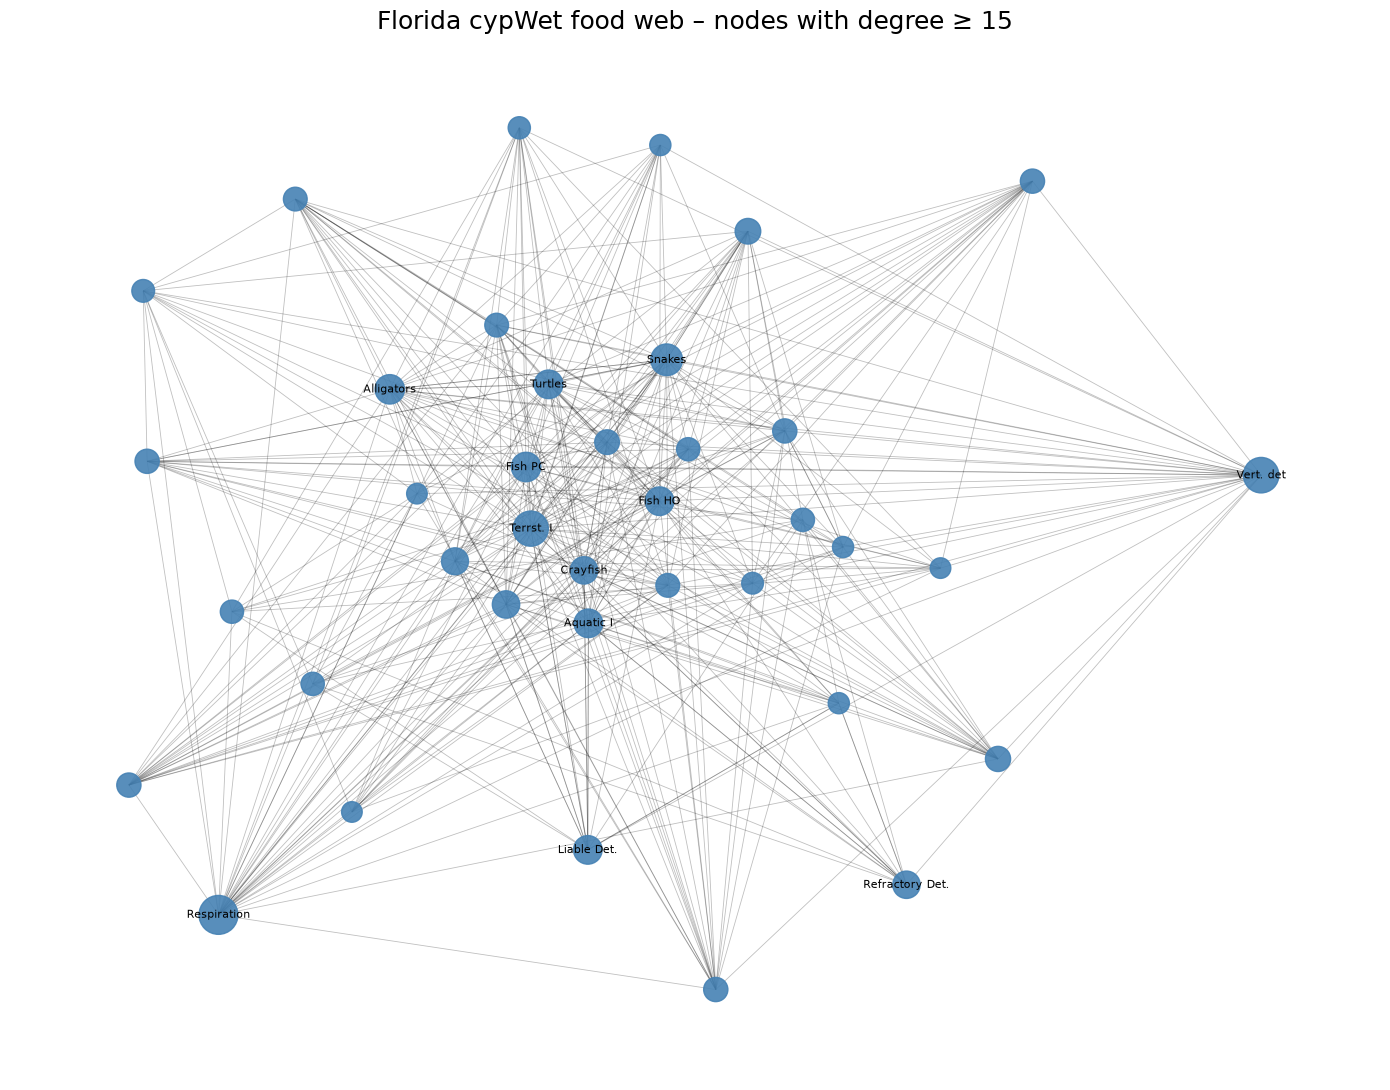

In [63]:
DEGREE_LIMIT = 15

deg = dict(G_fw.degree())
keep = [n for n, d in deg.items() if d >= DEGREE_LIMIT]
H = G_fw.subgraph(keep).copy()

print(f"Full: {G_fw.number_of_nodes()} nodes, {G_fw.number_of_edges()} edges")
print(f"deg >= {DEGREE_LIMIT}: {H.number_of_nodes()} nodes, {H.number_of_edges()} edges")

plt.figure(figsize=(14, 11))
pos = nx.spring_layout(H, k=2.0, seed=42, weight=None, iterations=100)

sizes = [40 + deg[n] * 12 for n in H.nodes()]
top = sorted(H.nodes(), key=lambda n: deg[n], reverse=True)[:12]
labels = {n: str(G_fw.nodes[n].get("name", n))[:18] for n in top}

nx.draw_networkx_nodes(H, pos, node_size=sizes, node_color="steelblue", alpha=0.9)
nx.draw_networkx_edges(H, pos, alpha=0.25, width=0.6, arrows=False)
nx.draw_networkx_labels(H, pos, labels=labels, font_size=8)

plt.title(f"Florida {NAME} food web – nodes with degree ≥ {DEGREE_LIMIT}", fontsize=18)
plt.axis("off")
plt.tight_layout()
plt.show()

- Here the directed edges appear. Because the direction of the edges matter, it is even harder, to make the visualization readable.

**cypWet:** cypress wetlands, **wet** season (South Florida food webs).  
Edges = **transfers of material or energy** between ecosystem compartments  

Animals with in-degree > 10: 17 nodes, 67 edges
  in=24  Snakes
  in=23  Alligators
  in=21  Other Herons
  in=21  Turtles
  in=20  Kites & Hawks
  in=20  Egrets
  in=20  Wood stork
  in=20  Owls
  in=18  GB Heron
  in=17  G Fox
  in=15  White ibis
  in=15  Raccoon
  in=14  Fish PC
  in=13  Mink
  in=12  Pelecaniformes
  in=12  Gruiformes
  in=11  Fish HO


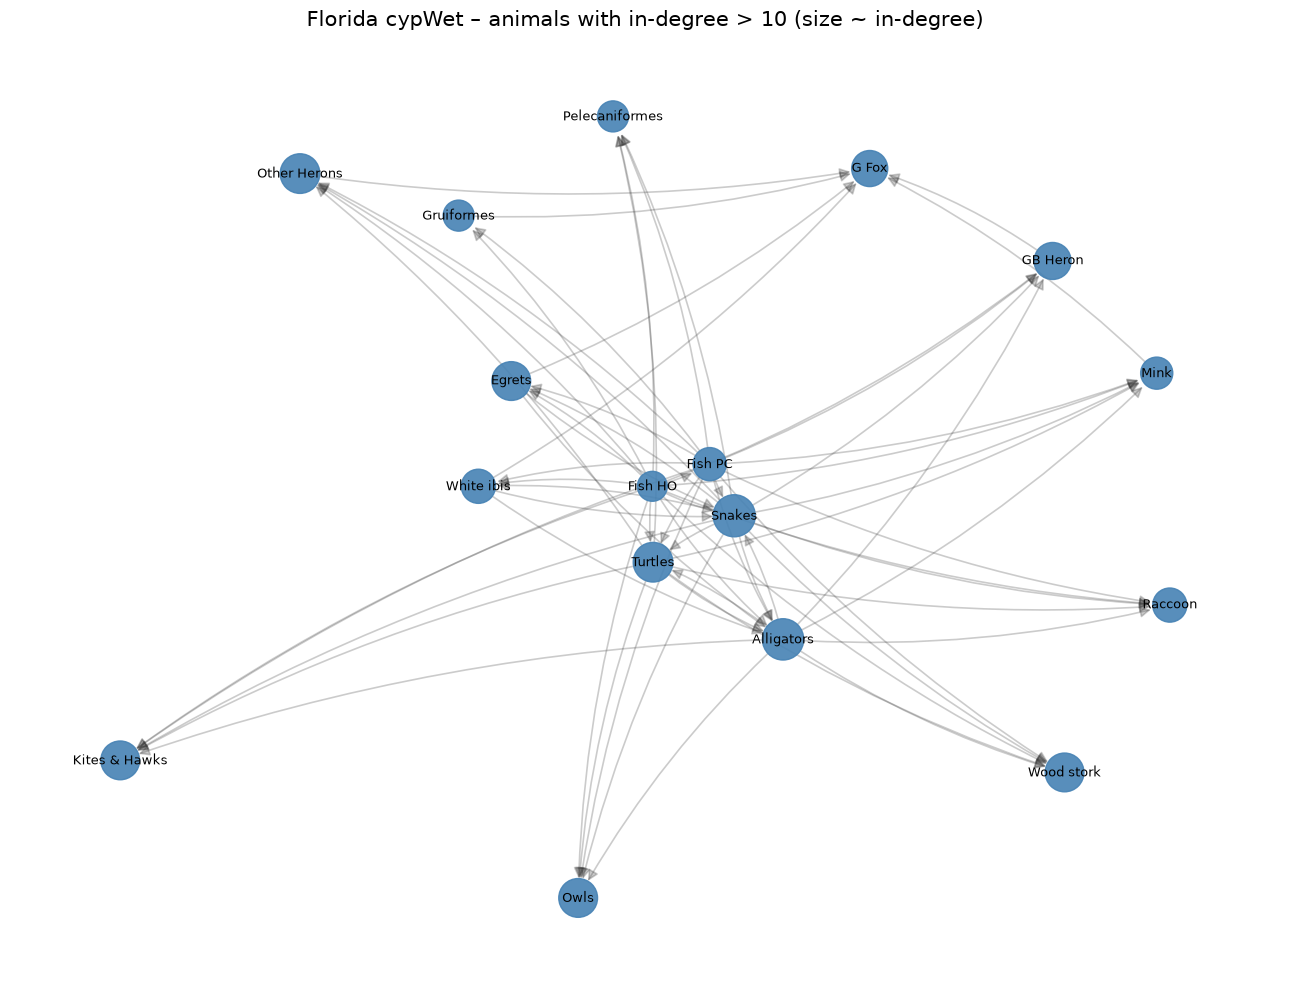

In [71]:
IN_DEGREE_MIN = 10
# only animals
ANIMAL_IDS = {n for n, d in G_fw.nodes(data=True) if 15 <= n <= 65}

in_deg = dict(G_fw.in_degree())
keep = [n for n in ANIMAL_IDS if in_deg[n] > IN_DEGREE_MIN]
H = G_fw.subgraph(keep).copy()

print(f"Animals with in-degree > {IN_DEGREE_MIN}: {H.number_of_nodes()} nodes, {H.number_of_edges()} edges")
for n in sorted(H.nodes(), key=lambda x: -in_deg[x]):
    print(f"  in={in_deg[n]:2d}  {H.nodes[n]['name']}")

plt.figure(figsize=(13, 10))
pos = nx.spring_layout(H, k=2.4, seed=42, weight=None, iterations=120)

sizes = [80 + in_deg[n] * 35 for n in H.nodes()]  # size ~ number of incoming edges
labels = {n: H.nodes[n]["name"] for n in H.nodes()}

nx.draw_networkx_nodes(H, pos, node_size=sizes, node_color="steelblue", alpha=0.9)
nx.draw_networkx_labels(H, pos, labels=labels, font_size=9)
nx.draw_networkx_edges(
    H,
    pos,
    width=1.2,
    alpha=0.25,
    edge_color="0.2",
    arrows=True,
    arrowstyle="-|>",
    arrowsize=16,
    connectionstyle="arc3,rad=0.08",
    node_size=sizes,
    min_source_margin=10,
    min_target_margin=14,
)

plt.title(
    f"Florida {NAME} – animals with in-degree > {IN_DEGREE_MIN} (size ~ in-degree)",
    fontsize=15,
)
plt.axis("off")
plt.tight_layout()
plt.show()


- The directed edges distribution is heterogenous as well, as usually many prey animals feed a smaller group of predators. 
- Artificial nodes (Input / Output / Respiration) remind that real networks may mix different terminologies and node types, and it is important to be able to choose what one wants to visualize/study.

# data 3 

**Data Source Information:**

* **Dataset:** Camp Data
* **Author:** UCINET (Borgatti, S.P., Everett, M.G., and Freeman, L.C.)
* **Source:** https://sites.google.com/site/ucinetsoftware/datasets/camp-data
* **Modifications:** None
* **License:** Academic/Educational use.

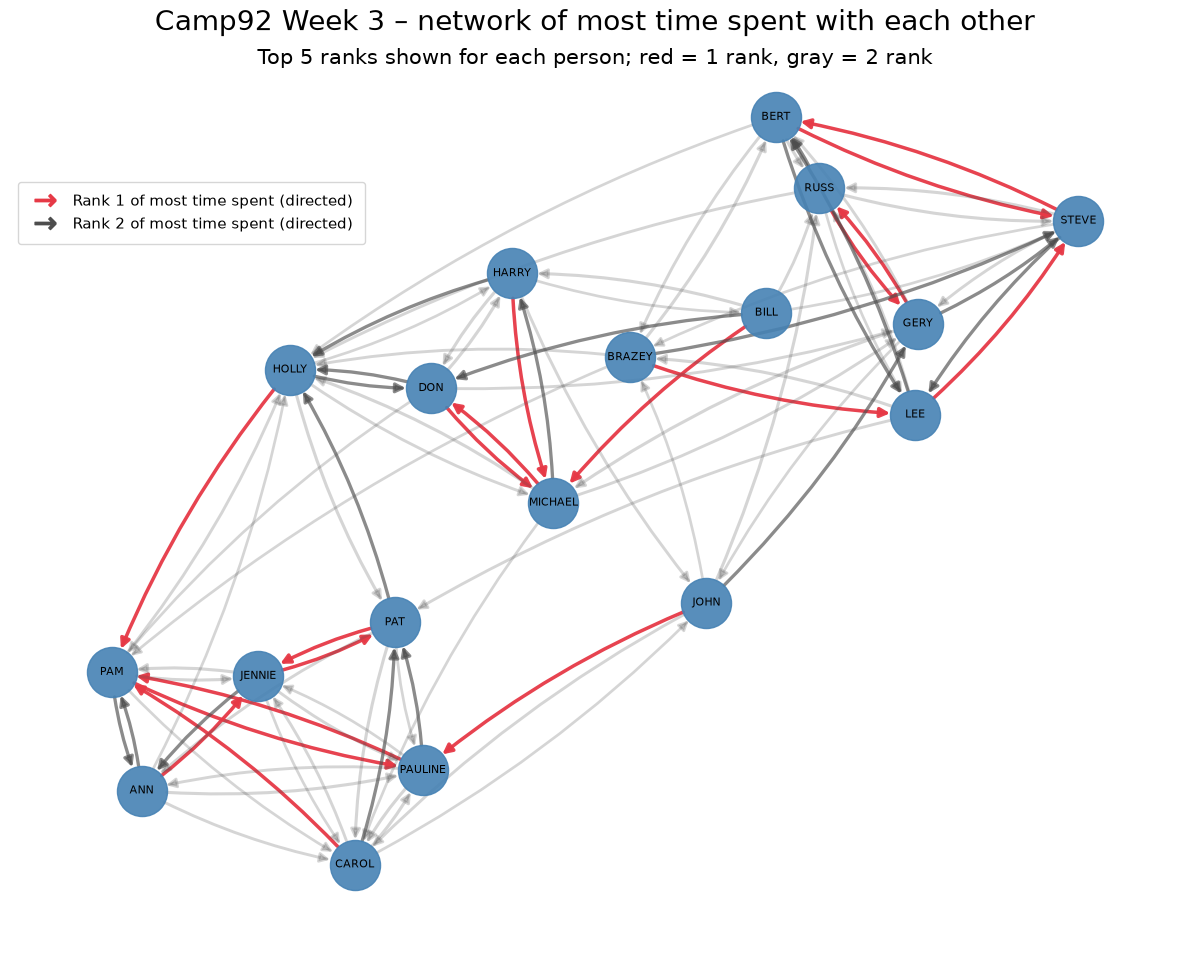

In [104]:
DATA = Path("data/camp92")
header = (DATA / "Camp92.##h").read_bytes()
raw = np.frombuffer((DATA / "Camp92.##d").read_bytes(), dtype="<f4")
mats = raw.reshape(2, 18, 18)

# labels
names = re.findall(rb"[\x20-\x7e]{2,}", header)
skip = {b"DATE:", b"Week_2", b"Week_3"}
people = []
for s in names:
    if s in skip or s.startswith(b"Camp92") or s.startswith(b"8Camp"):
        continue
    people.append(s.decode())
people = people[:18]
# print(people)

WEEK = 1  #1 = Week_3
RANK_MAX = 5  # max 5 ranks per person

M = mats[WEEK]
G = nx.DiGraph()
G.add_nodes_from(people)

for i, src in enumerate(people):
    for j, dst in enumerate(people):
        if i == j:
            continue
        rank = float(M[i, j])
        if rank <= 0 or rank > RANK_MAX:
            continue
        # invert the weights
        time_weight = 18.0 - rank
        G.add_edge(src, dst, rank=rank, weight=time_weight)

# print(f"Week {WEEK+2}: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")

plt.figure(figsize=(12, 10))
pos = nx.spring_layout(G, k=3, seed=42, weight="weight", iterations=100)

# edge styling
rank1_edges = []
rank2_edges = []
other_edges = []
widths = []
edge_list = []
for u, v, d in G.edges(data=True):
    r = int(d["rank"])
    edge_width = 0.13 + 0.14 * d["weight"]
    edge_list.append((u, v))
    widths.append(edge_width)
    # separate by rank
    if r == 1:
        rank1_edges.append((u, v))
    elif r == 2:
        rank2_edges.append((u, v))
    else:
        other_edges.append((u, v))

# node sizes
node_size = 1300

nx.draw_networkx_nodes(G, pos, node_size=node_size, node_color="steelblue", alpha=0.9)
nx.draw_networkx_labels(G, pos, font_size=8)

# different widths for different edges
def edge_widths_for(edges):
    idxs = [edge_list.index(e) for e in edges]
    return [widths[i] for i in idxs]

arrows = True

# rank 1 edges
if rank1_edges:
    nx.draw_networkx_edges(
        G, pos,
        edgelist=rank1_edges,
        width=edge_widths_for(rank1_edges),
        alpha=0.95,
        edge_color="#e63946",
        arrows=arrows,
        arrowstyle="-|>",
        arrowsize=14,
        connectionstyle="arc3,rad=0.08",
        node_size=node_size,
    )

# rank 2 edges
if rank2_edges:
    nx.draw_networkx_edges(
        G, pos,
        edgelist=rank2_edges,
        width=edge_widths_for(rank2_edges),
        alpha=0.65,
        edge_color="0.3",
        arrows=arrows,
        arrowstyle="-|>",
        arrowsize=14,
        connectionstyle="arc3,rad=0.08",
        node_size=node_size,
    )

# rest
if other_edges:
    nx.draw_networkx_edges(
        G, pos,
        edgelist=other_edges,
        width=edge_widths_for(other_edges),
        alpha=0.23,
        edge_color="0.3",
        arrows=arrows,
        arrowstyle="-|>",
        arrowsize=14,
        connectionstyle="arc3,rad=0.08",
        node_size=node_size,
    )

red_arrow = mlines.Line2D([], [], color="#e63946", marker=r'${\rightarrow}$', linestyle='None',
                          markersize=15, label="Rank 1 of most time spent (directed)")
gray_arrow = mlines.Line2D([], [], color="0.3", marker=r'${\rightarrow}$', linestyle='None',
                          markersize=15, label="Rank 2 of most time spent (directed)")
plt.legend(handles=[red_arrow, gray_arrow], fontsize=11, loc='upper left', frameon=True, borderpad=0.8, bbox_to_anchor=(0, 0.85))

plt.title(f"Camp92 Week {WEEK+2} – network of most time spent with each other", fontsize=20)
plt.suptitle(f"Top 5 ranks shown for each person; red = 1 rank, gray = 2 rank", fontsize=15, y=0.91)
plt.axis("off")
plt.tight_layout()
plt.show()

- Asymmetry, which is common in real survey networks. Person X will choose Y as top 1 but won't be chosen as top 1 by Y.

# data 4

**Data Source Information:**

* **Dataset:** Family Planning in Korea
* **Author:** UCINET (Rogers, E.M., & Kincaid, D.L.)
* **Source:** https://sites.google.com/site/ucinetsoftware/datasets/family-planning-in-korea
* **Modifications:** None
* **License:** Academic/Educational use.

39 69
['v25', 'v11', 'v62', 'v31', 'v22', 'v6', 'v16', 'v17', 'v19', 'v29']


/var/folders/3z/lljdpnns22b_zsxsy4kc5khc0000gn/T/ipykernel_67767/2629662105.py:21: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


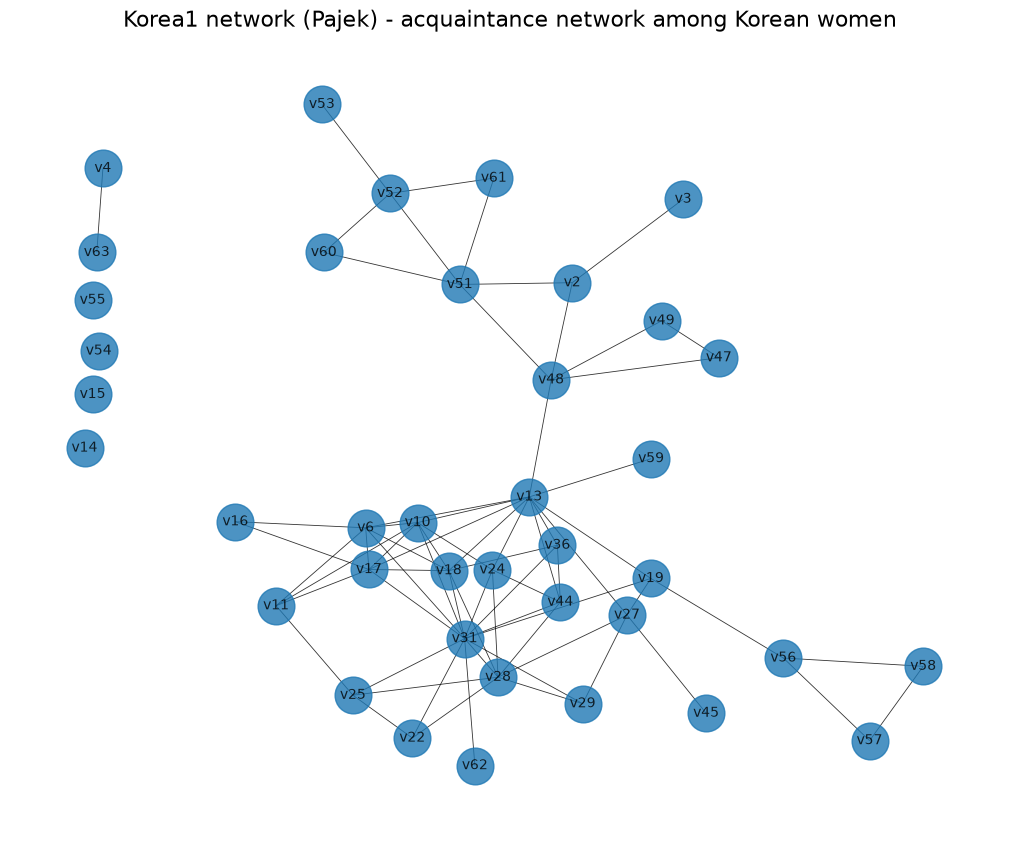

In [133]:
path = Path("data/Korea/Korea1.net")
G = nx.read_pajek(path)

G = nx.Graph(G)

print(G.number_of_nodes(), G.number_of_edges())
print(list(G.nodes())[:10])

pos = {
    n: (float(G.nodes[n]["x"]), float(G.nodes[n]["y"]))
    for n in G.nodes()
    if "x" in G.nodes[n] and "y" in G.nodes[n]
}
if len(pos) < G.number_of_nodes():
    pos = nx.spring_layout(G, seed=42)

plt.figure(figsize=(10, 8))
nx.draw(G, pos, node_size=700, width=0.6, alpha=0.8, with_labels=True, font_size=10)
plt.title("Korea1 network (Pajek) - acquaintance network among Korean women", fontsize=16)
plt.axis("off")
plt.tight_layout()
plt.show()

- Community structure visible (high clustering) + heavy-tailed distribution.
- Individuals completely isolated, which rather not happens in real-life, and if so, a lot more likely in small networks.

# data 5

**Data Source Information:**

* **Dataset:** Dolphins
* **Author:** David Lusseau (via UCINET)
* **Source:** https://sites.google.com/site/ucinetsoftware/datasets/dolphins
* **Modifications:** None
* **License:** Academic/Educational use.

62 159


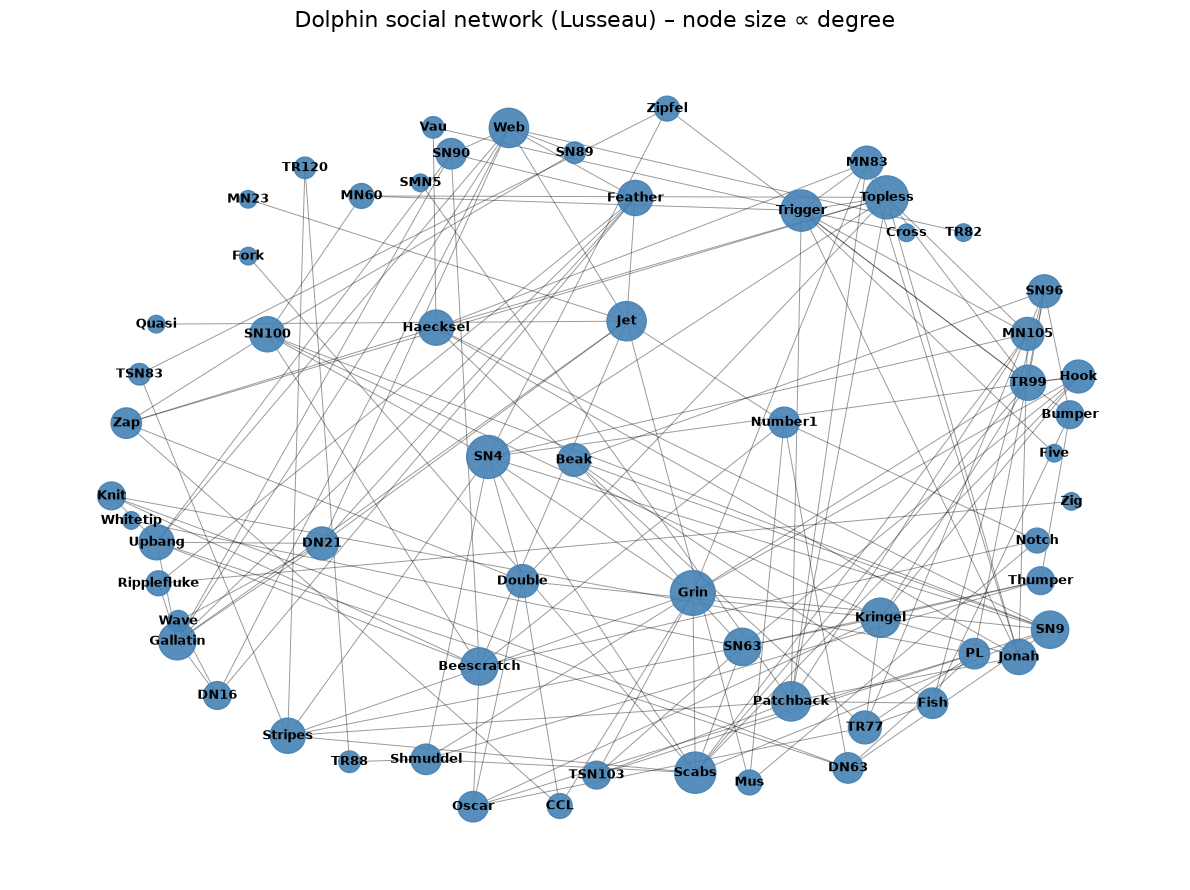

In [134]:
path = Path("data/Dolphins.txt")
G = nx.read_gml(path)
print(G.number_of_nodes(), G.number_of_edges())
deg = dict(G.degree())
sizes = [80 + deg[n] * 80 for n in G.nodes()]
pos = nx.spring_layout(G, seed=420, k=1.8)
plt.figure(figsize=(12, 9))
nx.draw_networkx_nodes(G, pos, node_size=sizes, node_color="steelblue", alpha=0.9)
nx.draw_networkx_edges(G, pos, width=0.7, alpha=0.4)
nx.draw_networkx_labels(G, pos, font_size=9, font_weight="bold")
plt.title("Dolphin social network (Lusseau) – node size ∝ degree", fontsize=16)
plt.axis("off")
plt.tight_layout()
plt.show()


- Community structure visible (high clustering) + heavy-tailed distribution.
- Relatively sparse, BUT to get from one to another node, we would only need probably MAX 3 if not 2 "handshakes"

## P2.3 Features of real networks (on our examples)

### 1. A Song of Ice and Fire (interaction network)
#### 1.1
- The full graph of around 800 nodes is completely nonreadable. Typical and obvious for real-life networks.
#### 1.2
- Filtering to higher degree characters shows a heavy-tailed degree distribution. There are a few hubs (e.g. Jon), communities (around Tyrion) and a lot of low-degree characters.
#### 1.3
- The multilayer (books 1–5) view shows temporal change. Most degree vertices (Characters) appear and disappear across books. This shows that real-life networks evolve, and sometimes start revolving around different/new nodes.


</br>
</br>
</br>

### 2. Florida food web 
#### 2.1
- Here the directed edges appear. Because the direction of the edges matter, it is even harder, to make the visualization readable.
#### 2.2
- The directed edges distribution is heterogenous as well, as usually many prey animals feed a smaller group of predators. 
- Artificial nodes (Input / Output / Respiration) remind that real networks may mix different terminologies and node types, and it is important to be able to choose what one wants to visualize/study.

</br>
</br>
</br>

### 3. Camp92 (ranked interactions)
- Asymmetry, which is common in real survey networks. Person X will choose Y as top 1 but won't be chosen as top 1 by Y.

</br>
</br>
</br>

### 4. Korea
- Community structure visible (high clustering) + heavy-tailed distribution.
- Individuals completely isolated, which rather not happens in real-life, and if so, a lot more likely in small networks.

</br>
</br>
</br>

### 5. Dolphins
- Community structure visible (high clustering) + heavy-tailed distribution.
- Relatively sparse, BUT to get from one to another node, we would only need probably MAX 3 if not 2 "handshakes"